# Stronger acoustic representation: v2

Yeh original baseline ka alag improvement experiment hai. Same actors/split, training-only grouped search, five required classifiers. [Protocol](PROTOCOL.md) aur [Roman Urdu KT](KT_ADDENDUM.md) parhein. **Test reused hai; naya untouched test nahi.** Source cells reusable modules ka code dikhate hain; heavy work verified caches se resume hota hai.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/audio_features.py').exists())
sys.path.insert(0,str(ROOT))
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMBA_NUM_THREADS']:
    os.environ[key]='1'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code
from threadpoolctl import threadpool_limits
from experiments.representation_v2.run import guard, load_data, select, evaluate, candidates
from experiments.representation_v2.features import predict_emotion
from experiments.representation_v2.verify import verify
OUT = ROOT/'experiments/representation_v2'
print('Original files verified:',guard(ROOT))
manifest, matrices = load_data(ROOT)
display(manifest.groupby('split').agg(clips=('filename','size'),actors=('actor','nunique')))
print({name: value.shape for name,value in matrices.items()})

Original files verified: 55


,clips,actors
split,,
test,1140,14
train,5149,63
validation,1146,14


{'egemaps': (7435, 88), 'fusion': (7435, 361)}


## Features aur training recipe
88 eGeMAPS raw waveform se; fusion mein 273 low-pass-filtered baseline features bhi. Fixed acoustic extractor hai, pretrained emotion classifier nahi. Shrinkage LDA aur scaling har training fold ke andar fit hote hain.

In [2]:
display(pd.Series(json.loads((OUT/'features_metadata.json').read_text())['names'],name='88 eGeMAPSv02 columns').to_frame())
display(Code((OUT/'features.py').read_text(),language='python'))
display(Code((OUT/'run.py').read_text(),language='python'))

,88 eGeMAPSv02 columns
0,F0semitoneFrom27.5Hz_sma3nz_amean
1,F0semitoneFrom27.5Hz_sma3nz_stddevNorm
2,F0semitoneFrom27.5Hz_sma3nz_percentile20.0
3,F0semitoneFrom27.5Hz_sma3nz_percentile50.0
4,F0semitoneFrom27.5Hz_sma3nz_percentile80.0
...,...
83,MeanVoicedSegmentLengthSec
84,StddevVoicedSegmentLengthSec
85,MeanUnvoicedSegmentLength
86,StddevUnvoicedSegmentLength


"""Fixed eGeMAPSv02 features; no pretrained emotion model or corpus fitting."""
from pathlib import Path
import hashlib
import json
import numpy as np
import opensmile
from src.audio_features import load_audio, extract_file


def extractor():
    return opensmile.Smile(feature_set=opensmile.FeatureSet.eGeMAPSv02,
                          feature_level=opensmile.FeatureLevel.Functionals,
                          num_workers=1)


def egemaps(path, smile=None):
    smile = smile or extractor()
    values = smile.process_signal(load_audio(path).astype(np.float32), 16000)
    array = values.to_numpy(dtype=np.float64).ravel()
    if array.shape != (88,) or not np.isfinite(array).all():
        raise ValueError(f"Invalid eGeMAPS features: {path}")
    return array


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def extract_all(root, manifest):
    out = root / 'experiments/representation_v2'
    identity = {'manifest': sha(root / 'data/split_manifest.csv'),
                'source': sha(Path(__file__)), 'opensmile': opensmile.__version__,
                'audio_source': sha(root / 'src/audio_features.py')}
    cache = out / 'features.npz'
    metadata = out / 'features_metadata.json'
    if cache.exists():
        assert json.loads(metadata.read_text())['identity'] == identity, 'Stale feature cache'
        with np.load(cache) as data:
            assert np.array_equal(data['filenames'], manifest.filename.to_numpy())
            return data['egemaps']
    smile = extractor()
    rows = []
    partial = out / 'feature_progress.npz'
    if partial.exists():
        with np.load(partial) as data:
            assert json.loads(str(data['identity'])) == identity
            rows = list(data['egemaps'])
    for i in range(len(rows), len(manifest)):
        row = manifest.iloc[i]
        if sha(row.path) != row.sha256:
            raise ValueError(f'Audio changed: {row.filename}')
        rows.append(egemaps(row.path, smile))
        if (i+1) % 250 == 0:
            with partial.with_suffix('.partial').open('wb') as handle:
                np.savez_compressed(handle, identity=json.dumps(identity), egemaps=rows)
            partial.with_suffix('.partial').replace(partial)
            print(f'eGeMAPS {i+1}/{len(manifest)}', flush=True)
    values = np.asarray(rows)
    with cache.with_suffix('.partial').open('wb') as handle:
        np.savez_compressed(handle, egemaps=values, filenames=manifest.filename.to_numpy(dtype=str))
    cache.with_suffix('.partial').replace(cache)
    metadata.write_text(json.dumps({'identity': identity, 'names': smile.feature_names,
                                    'shape': list(values.shape)}, indent=2))
    return values


def predict_emotion(audio_path, project_root=None):
    """Predict using trusted local v2 artifacts and the exact saved feature recipe."""
    import joblib
    from .run import identity, load_data
    root = Path(project_root) if project_root else Path(__file__).resolve().parents[2]
    out = root / 'experiments/representation_v2'
    frozen = json.loads((out / 'selection.json').read_text())
    assert identity(root) == frozen['identity'], 'Experiment inputs changed'
    record = joblib.load(out / 'winner.joblib')
    vector = egemaps(audio_path)
    if record['representation'] == 'fusion':
        vector = np.r_[extract_file(audio_path, filtered=True)[0], vector]
    return str(record['pipeline'].predict(vector[None, :])[0])

"""Training-only grouped search, validation selection, then one cached test reuse."""
import os
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS']:
    os.environ[key] = '1'
from pathlib import Path
import hashlib
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits
from src.experiments import load_inputs, score_predictions, save_artifact
from src.rbf_kernel import TrainingRBFKernel
from .features import extract_all, sha

ROOT = Path(__file__).resolve().parents[2]


def guard(root):
    out = root / 'experiments/representation_v2'
    path = out / 'baseline_hashes.json'
    if not path.exists():
        files = [p for directory in ['src', 'artifacts', 'reports', 'docs', 'notebooks']
                 for p in (root/directory).rglob('*') if p.is_file() and '__pycache__' not in str(p)]
        files += [root/'README.md', root/'requirements.txt', root/'requirements-lock.txt', root/'data/split_manifest.csv']
        path.write_text(json.dumps({str(p.relative_to(root)): sha(p) for p in files}, indent=2))
    frozen = json.loads(path.read_text())
    assert all((root/p).exists() and sha(root/p) == digest for p, digest in frozen.items()), 'Baseline changed'
    return len(frozen)


def load_data(root):
    manifest, baseline = load_inputs(root)
    extra = extract_all(root, manifest)
    assert extra.shape == (len(manifest), 88) and np.isfinite(extra).all()
    return manifest, {'egemaps': extra, 'fusion': np.c_[baseline['filtered'], extra]}


def identity(root):
    digest = hashlib.sha256()
    for name in ['data/split_manifest.csv', 'artifacts/features.npz', 'src/audio_features.py',
                 'src/experiments.py', 'src/rbf_kernel.py',
                 'experiments/representation_v2/features.py', 'experiments/representation_v2/run.py',
                 'experiments/representation_v2/requirements-lock.txt',
                 'experiments/representation_v2/features.npz', 'experiments/representation_v2/features_metadata.json']:
        digest.update(sha(root/name).encode())
    return digest.hexdigest()


def candidates():
    definitions = []
    for k in [9, 21]:
        definitions.append(('KNN', True, KNeighborsClassifier(n_neighbors=k, n_jobs=1)))
    for lda in [False, True]:
        for c in [0.01, 0.1, 1]:
            definitions.append(('Logistic Regression', lda, LogisticRegression(C=c, max_iter=1500, random_state=42)))
    for smoothing in [1e-9, 1e-5]:
        definitions.append(('GaussianNB', True, GaussianNB(var_smoothing=smoothing)))
    for c in [1, 10, 100]:
        for gamma in ['scale', 0.001]:
            definitions.append(('SVM', False, SVC(C=c, gamma=gamma)))
    for lda in [False, True]:
        for alpha in [0.01, 1]:
            definitions.append(('MLP', lda, MLPClassifier(hidden_layer_sizes=(64,), alpha=alpha,
                                learning_rate_init=0.001, max_iter=300, early_stopping=False, random_state=42)))
    for family, lda, classifier in definitions:
        steps = [('scale', StandardScaler())]
        if lda:
            steps.append(('lda', LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')))
        if family == 'SVM':
            steps.append(('kernel', TrainingRBFKernel(gamma=classifier.gamma)))
            classifier = SVC(C=classifier.C, kernel='precomputed', cache_size=128)
        steps.append(('classifier', classifier))
        yield family, lda, Pipeline(steps)


def select(root=

## Training actors ki 3-fold search
40 configurations, 120 internal fits; CV se ten finalists. Original validation se winner. Warnings retain ki gayi hain; random-clip early stopping nahi.

In [3]:
frozen = select(ROOT)
search = pd.read_csv(OUT/'grouped_search.csv')
validation = pd.read_csv(OUT/'validation_results.csv')
display(search[['key','model','cv_macro_f1','cv_std','seconds','warnings']])
display(validation)
print('Validation-selected winner:',frozen['winner'])
print('CV candidates with warnings:',search.warnings.fillna('').ne('').sum())

,key,model,cv_macro_f1,cv_std,seconds,warnings
0,egemaps-0,KNN,0.431246,0.009985,1.858407,NaN
1,egemaps-1,KNN,0.452128,0.013007,1.235169,NaN
2,egemaps-2,Logistic Regression,0.476083,0.008829,0.487585,NaN
3,egemaps-3,Logistic Regression,0.495071,0.005729,0.806408,NaN
4,egemaps-4,Logistic Regression,0.495567,0.005933,1.504154,NaN
5,egemaps-5,Logistic Regression,0.459784,0.019920,0.353152,NaN
6,egemaps-6,Logistic Regression,0.458403,0.018222,0.336361,NaN
7,egemaps-7,Logistic Regression,0.456078,0.017332,0.347185,NaN
8,egemaps-8,GaussianNB,0.430196,0.023509,0.290320,NaN
9,egemaps-9,GaussianNB,0.430196,0.023509,0.294077,NaN


,key,representation,model,candidate,cv_macro_f1,cv_std,validation_accuracy,validation_macro_f1,validation_weighted_f1,validation_balanced_accuracy,train_accuracy,train_macro_f1,train_weighted_f1,train_balanced_accuracy,warnings
0,egemaps-1,egemaps,KNN,1,0.452128,0.013007,0.422339,0.416089,0.415456,0.424786,0.540299,0.536427,0.536091,0.542290,NaN
1,egemaps-4,egemaps,Logistic Regression,4,0.495567,0.005933,0.445899,0.438501,0.438183,0.448038,0.554282,0.549747,0.549375,0.555844,NaN
2,egemaps-8,egemaps,GaussianNB,8,0.430196,0.023509,0.419721,0.404165,0.403625,0.424062,0.476209,0.458780,0.457743,0.481213,NaN
3,egemaps-15,egemaps,SVM,15,0.502644,0.003399,0.454625,0.446341,0.445771,0.456231,0.646728,0.643764,0.643834,0.647627,NaN
4,egemaps-17,egemaps,MLP,17,0.506079,0.003207,0.455497,0.449122,0.447696,0.458314,0.673917,0.672956,0.673084,0.675418,NaN
5,fusion-1,fusion,KNN,1,0.533955,0.001288,0.506108,0.499442,0.499757,0.507357,0.651583,0.649905,0.649681,0.652701,NaN
6,fusion-2,fusion,Logistic Regression,2,0.547792,0.002719,0.499127,0.492989,0.493394,0.499841,0.644203,0.642160,0.641849,0.645154,NaN
7,fusion-8,fusion,GaussianNB,8,0.537693,0.008359,0.512216,0.504272,0.504259,0.514377,0.621091,0.618968,0.618918,0.623201,NaN
8,fusion-13,fusion,SVM,13,0.556141,0.007694,0.513962,0.509060,0.509500,0.514465,0.830258,0.829892,0.829770,0.831027,NaN
9,fusion-19,fusion,MLP,19,0.548789,0.003335,0.513962,0.508372,0.508934,0.514473,0.645756,0.644023,0.643758,0.646794,NaN


Validation-selected winner: fusion-13
CV candidates with warnings: 4


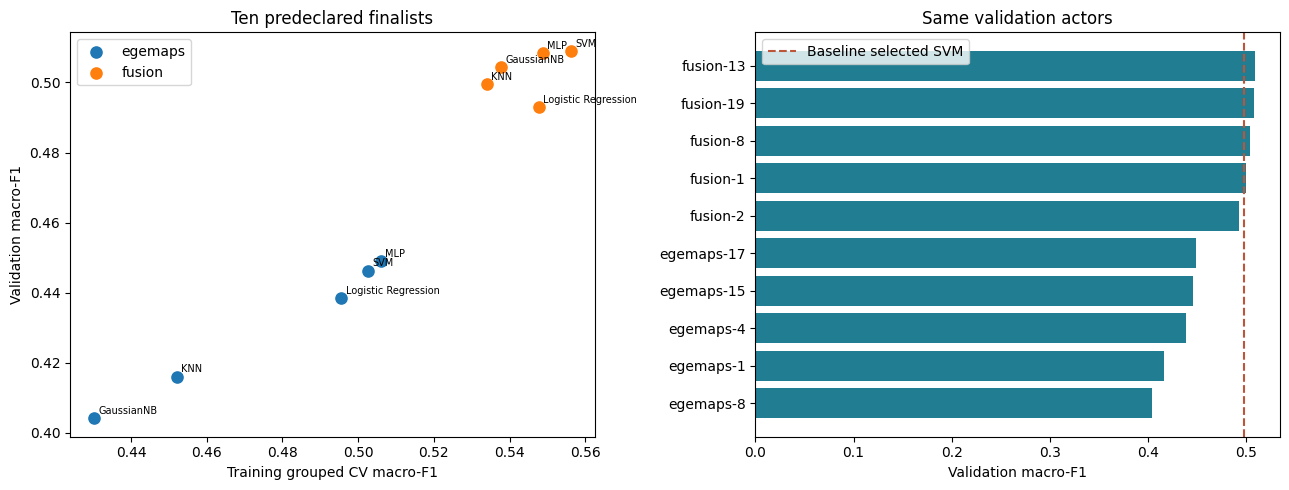

In [4]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
for rep, frame in validation.groupby('representation'):
    axes[0].scatter(frame.cv_macro_f1,frame.validation_macro_f1,label=rep,s=65)
    for row in frame.itertuples():
        axes[0].annotate(row.model,(row.cv_macro_f1,row.validation_macro_f1),fontsize=7,xytext=(3,3),textcoords='offset points')
axes[0].set(xlabel='Training grouped CV macro-F1',ylabel='Validation macro-F1',title='Ten predeclared finalists')
axes[0].legend()
ranked = validation.sort_values('validation_macro_f1')
axes[1].barh(ranked.key,ranked.validation_macro_f1,color='#207d92')
axes[1].axvline(0.4982648836,color='#bb563b',linestyle='--',label='Baseline selected SVM')
axes[1].set(xlabel='Validation macro-F1',title='Same validation actors')
axes[1].legend()
fig.tight_layout(); fig.savefig(OUT/'validation_comparison.png',dpi=140); plt.show()

## Selection freeze ke baad reused test
Original baseline mein test dekha ja chuka hai. Ab one selected representative per family evaluate hota hai aur cache save hoti hai. Test se model selection/tuning nahi hoti.

,key,model,accuracy,macro_f1,weighted_f1,balanced_accuracy
0,fusion-13,SVM,0.577193,0.572909,0.573529,0.575217
1,fusion-19,MLP,0.562281,0.559793,0.560514,0.560374
2,fusion-8,GaussianNB,0.557018,0.552195,0.552747,0.556432
3,fusion-1,KNN,0.542105,0.539714,0.540495,0.540376
4,fusion-2,Logistic Regression,0.569298,0.564385,0.565218,0.567511


{'winner': 'fusion-13',
 'baseline_winner': 'SVM',
 'validation_macro_f1_gain': 0.010795449185086459,
 'validation_accuracy_gain': 0.012216404886561949,
 'reused_test_macro_f1_gain': 0.023249749620979254,
 'reused_test_accuracy_gain': 0.024561403508771895,
 'validation_paired_interval': {'resamples': 1000,
  'unit': 'paired actor',
  'accuracy_difference_95': [-0.0026224924375099295, 0.02700348432055749],
  'macro_f1_difference_95': [-0.006505621646060594, 0.024927317148018366]},
 'test_paired_interval': {'resamples': 1000,
  'unit': 'paired actor',
  'accuracy_difference_95': [-0.000872676758878052, 0.04825898587933251],
  'macro_f1_difference_95': [-0.0024299019284275574, 0.04740824941843105]}}

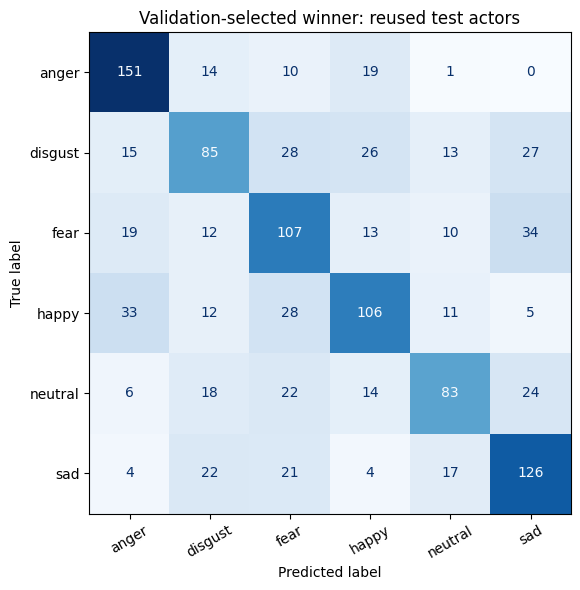

,precision,recall,f1-score,support
anger,0.662281,0.774359,0.713948,195.000000
disgust,0.521472,0.438144,0.476190,194.000000
fear,0.495370,0.548718,0.520681,195.000000
happy,0.582418,0.543590,0.562334,195.000000
neutral,0.614815,0.497006,0.549669,167.000000
sad,0.583333,0.649485,0.614634,194.000000
accuracy,0.577193,0.577193,0.577193,0.577193
macro avg,0.576615,0.575217,0.572909,1140.000000
weighted avg,0.575719,0.577193,0.573529,1140.000000


In [5]:
test = evaluate(ROOT)
display(test)
display(json.loads((OUT/'comparison.json').read_text()))
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
predictions = pd.read_csv(OUT/'test_predictions.csv')
labels = ['anger','disgust','fear','happy','neutral','sad']
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix(predictions.emotion,predictions[frozen['winner']],labels=labels),display_labels=labels).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title('Validation-selected winner: reused test actors')
ax.tick_params(axis='x',rotation=30)
fig.tight_layout(); fig.savefig(OUT/'winner_confusion.png',dpi=140); plt.show()
display(pd.DataFrame(json.loads((OUT/'winner_classification.json').read_text())).T)

## Raw WAV inference aur checks
Scaler, LDA aur kernel references training-only hain. File se feature extraction karke saved predictions ke saath consistency check hoti hai.

In [6]:
example = manifest.loc[manifest.split.eq('validation')].iloc[0]
with threadpool_limits(1):
    prediction = predict_emotion(example.path,ROOT)
print(example.filename,'| intended:',example.emotion,'| predicted:',prediction)
display(verify(ROOT))

D:\ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1007_DFA_ANG_XX.wav | intended: anger | predicted: anger


{
  "baseline_files_preserved": 55,
  "fixed_actor_disjoint_split": {
    "test": 14,
    "train": 63,
    "validation": 14
  },
  "three_grouped_folds_disjoint": true,
  "validation_only_winner_and_complete_search": true,
  "all_ten_models_training_only_scaling_and_kernel": true,
  "raw_wav_cache_and_saved_inference_agree": true,
  "five_families_evaluated_after_freeze": true,
  "baseline_files_preserved_after_checks": 55
}


{'baseline_files_preserved': 55,
 'fixed_actor_disjoint_split': {'test': 14, 'train': 63, 'validation': 14},
 'three_grouped_folds_disjoint': True,
 'validation_only_winner_and_complete_search': True,
 'all_ten_models_training_only_scaling_and_kernel': True,
 'raw_wav_cache_and_saved_inference_agree': True,
 'five_families_evaluated_after_freeze': True,
 'baseline_files_preserved_after_checks': 55}

## Interpretation
Measured point gain ko guaranteed future accuracy mat samjhein. Paired actor intervals selection/training uncertainty cover nahi karte. External corpus aur naye speakers par confirmation chahiye. Full utterance functionals ab bhi frame order discard karte hain. Original baseline aur uski KT unchanged hain.

In [7]:
display(Markdown((OUT/'comparison_report.md').read_text(encoding='utf-8')))

# Representation v2 - measured comparison

Date: 7 November 2026 (Asia/Karachi). Outcome: **improvement on reused validation actors**. Validation-selected winner: **fusion-13 / SVM**. Baseline is preserved byte-for-byte; no original report/notebook/KT was replaced.

## Main comparison

| Metric | Original selected SVM | New selected SVM | Difference |
| --- | --- | --- | --- |
| Training accuracy | 0.9771 | 0.8303 | descriptive |
| Validation accuracy | 0.5017 | 0.5140 | +1.22 percentage points |
| Validation macro-F1 | 0.4983 | 0.5091 | +0.0108 |
| Reused test accuracy | 0.5526 | 0.5772 | +2.46 percentage points |
| Reused test macro-F1 | 0.5497 | 0.5729 | +0.0232 |

## Method and selection evidence

Two fixed representations: 88 unfiltered eGeMAPSv02 functionals and a 361-feature fusion with the original 273 filtered features. This compares a package of representation and regularization/search changes; it is not a causal ablation that assigns every gain exclusively to eGeMAPS. Original actor allocation, labels and data exclusions are unchanged. Details, grids, citations, licensing and rationale are in [PROTOCOL.md](PROTOCOL.md).

Forty configurations underwent training-only 3-fold actor-grouped validation (120 fits). One configuration per family and representation was refitted on the 5,149 training clips only. Ten finalists were compared using validation macro-F1, accuracy and lexical key. The winner's grouped training CV macro-F1 is 0.5561 (fold SD 0.0077). This is a selected CV estimate, not nested CV or a new external result. No train+validation refit or random-clip early stopping occurred. Warning messages are retained in the search and finalist CSVs; max_iter warnings mean some optimizers did not meet their convergence criterion.

| key | model | cv_macro_f1 | train_macro_f1 | validation_macro_f1 | validation_accuracy |
| --- | --- | --- | --- | --- | --- |
| egemaps-1 | KNN | 0.4521 | 0.5364 | 0.4161 | 0.4223 |
| egemaps-4 | Logistic Regression | 0.4956 | 0.5497 | 0.4385 | 0.4459 |
| egemaps-8 | GaussianNB | 0.4302 | 0.4588 | 0.4042 | 0.4197 |
| egemaps-15 | SVM | 0.5026 | 0.6438 | 0.4463 | 0.4546 |
| egemaps-17 | MLP | 0.5061 | 0.6730 | 0.4491 | 0.4555 |
| fusion-1 | KNN | 0.5340 | 0.6499 | 0.4994 | 0.5061 |
| fusion-2 | Logistic Regression | 0.5478 | 0.6422 | 0.4930 | 0.4991 |
| fusion-8 | GaussianNB | 0.5377 | 0.6190 | 0.5043 | 0.5122 |
| fusion-13 | SVM | 0.5561 | 0.8299 | 0.5091 | 0.5140 |
| fusion-19 | MLP | 0.5488 | 0.6440 | 0.5084 | 0.5140 |

## Five required families on reused test actors

One validation-selected representation per family was evaluated after selection.json was frozen. Test results never chose the winner. Test output is cached on rerun; do not tune using it.

| key | model | accuracy | macro_f1 | balanced_accuracy |
| --- | --- | --- | --- | --- |
| fusion-13 | SVM | 0.5772 | 0.5729 | 0.5752 |
| fusion-19 | MLP | 0.5623 | 0.5598 | 0.5604 |
| fusion-8 | GaussianNB | 0.5570 | 0.5522 | 0.5564 |
| fusion-1 | KNN | 0.5421 | 0.5397 | 0.5404 |
| fusion-2 | Logistic Regression | 0.5693 | 0.5644 | 0.5675 |

## Uncertainty and interpretation

Paired actor bootstrap (1,000 resamples, seed 42), new minus baseline:

- Validation macro-F1 difference 95% percentile interval: [-0.006505621646060594, 0.024927317148018366].
- Reused test macro-F1 difference 95% percentile interval: [-0.0024299019284275574, 0.04740824941843105].
- Reused test accuracy difference 95% percentile interval: [-0.000872676758878052, 0.04825898587933251].

Both models are evaluated on the same resampled actors. Intervals condition on fitted models and ignore training/selection uncertainty; the validation interval is especially optimistic because this same validation set selected the winner. A positive point difference is a measured gain on this allocation, not a guarantee or independent significance claim. Only 14 validation and 14 test actors are available. Full numeric intervals are in comparison.json.

The test actors had already been evaluated during the baseline. This is explicitly a **reused test**, not a genuinely untouched test set. The shared validation actors are also a reused development holdout. A new corpus or independently collected speakers would be needed for stronger confirmation. Acted English speech, modified noise and intended filename labels limit generalization to natural speech and other microphones/languages. Voice-quality estimates may be noisy; full utterance functionals still discard frame order. This experiment does not prove why each error occurs, measure clean-reference SNR, or promise 80-90% accuracy.

## Reproducibility and deliverables

Open [improvement.ipynb](improvement.ipynb) in PyCharm using the existing .venv. See [README.md](README.md) for exact commands and inference. New requirements-lock.txt captures the extended environment; baseline dependency files remain unchanged. features_metadata.json lists every eGeMAPS column, grouped_folds.csv fixes internal actor assignments, grouped_search.csv records all fits, selection.json freezes validation choice, and winner.joblib retains training-fitted transforms. Only load trusted local joblib files. [KT_ADDENDUM.md](KT_ADDENDUM.md) explains the change in Roman Urdu. No commit, push or publication occurred.

## Additional real personal-voice evaluation

Twenty user microphone recordings: five each happy, disgust, sad and anger. One speaker/session; four supported target emotions, six possible model outputs. This separate personal evaluation never trains or selects the model.

- baseline: 5/20 correct; accuracy 25.0%; four-supported-class macro-F1 0.1801; fixed-six macro-F1 0.1201.
- improved: 5/20 correct; accuracy 25.0%; four-supported-class macro-F1 0.1042; fixed-six macro-F1 0.0694.

Do not directly compare four-supported-class F1 with six-supported-class CREMA-D F1. Self-reported intended emotions, one microphone/room, repeated sentence and correlated takes limit conclusions. This is not a multi-speaker external validation. Local evidence: `voice_evaluation\sessions\20261107_194332_9e11217c`; raw voice files remain ignored by Git.


## References
Eyben et al. GeMAPS, [DOI](https://doi.org/10.1109/TAFFC.2015.2457417); [openSMILE usage](https://audeering.github.io/opensmile-python/usage.html) and [license](https://audeering.github.io/opensmile-python/). Implementation assisted by OpenAI Codex; original third-party authors retain attribution. Full provenance, scope and educational-use licensing are in PROTOCOL.md.